# FIR sur les traces AVANT la SVD

Le pouls d'intensité de l'app (`Astronauts/data_visualizer_GUI/pulse_compute.py`) fait la SVD
sur les traces **brutes** (centrées-réduites), puis optimise une combinaison des composantes, et
ne filtre (FIR) que le pouls final. Ce notebook teste l'ordre inverse : **filtrer chaque trace
avant la SVD**, pour que les vecteurs singuliers ne dépensent pas leur rang à décrire la dérive,
le bruit haute fréquence et les résidus de recalage.

1. matrice `A` (T × N) : pixels de la choroïde, tiers central latéral (`ROI_WIDTH_MM`),
   `ROI_DEPTH_UM` sous le bord supérieur du masque, suivi frame par frame
   (`pulse_compute.rpe_band_traces`, la même région que l'app) ;
2. FIR passe-bande sur la dimension temporelle (`motion.filters._1d.spatio_temporal_filter`,
   `filtfilt`, donc sans déphasage), après interpolation sur une grille uniforme ;
3. SVD, 100 premiers vecteurs singuliers ;
4. combinaison linéaire optimisée (`OptimizedSpectralCombination`, portage de
   `detectPulseUsingSVD.m`, via `pulse_compute.optimized_combination`) ;
5. les vecteurs singuliers retenus : cours temporels, spectres, cartes spatiales, poids.

Deux normalisations (`NORMS`) croisées avec trois FIR (`FIRS`), soit six variantes :

| normalisation | avant le FIR |
|---|---|
| `non normalisé` | aucune -- la chaîne actuelle de l'app |
| `normalized_trace` | `PixelTraceSource.normalized_trace` (`motion/pulsation/traces/pixel.py`) : chaque frame divisée par son intensité moyenne sur les traces. Enlève le gain / l'éclairage commun à toute la ROI à une frame donnée -- et avec lui la part du pouls qui bat en phase dans toute la ROI |

| FIR | avant la SVD |
|---|---|
| `brut` | aucun -- la chaîne actuelle de l'app (référence) |
| `large` | `BAND_WIDE_BPM`, bande physiologique large, indépendante de la FC |
| `FC ±10 %` | la bande du FIR final de l'app : tout ce qui sort est forcément à la FC, l'optimisation n'a plus grand-chose à choisir |

Dans tous les cas chaque trace est ensuite centrée-réduite (après le FIR), comme dans l'app.
Le signe du pouls est fixé sur l'intensité moyenne **brute** de la ROI, pour les deux
normalisations (après `normalized_trace` la moyenne spatiale vaut 1 à chaque frame : elle ne
peut plus servir de référence).

Le pouls de chaque variante est comparé au pouls d'**épaisseur des masques** (critère
indépendant de l'intensité) : déphasage moyen et PLV sur le cœur du signal.

In [ ]:
import sys
from pathlib import Path

# Ordre impose par les DLL de l'env pyOR : pandas, puis torch, puis le reste.
import pandas as pd
import torch  # noqa: F401
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.interpolate import interp1d

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "Astronauts" / "data_visualizer_GUI"))
import catalog  # noqa: E402
import pulse_compute as pc  # noqa: E402
from ocularrigidity.motion.filters._1d import spatio_temporal_filter  # noqa: E402
from ocularrigidity.motion.projection._1d import project_into_separable_components  # noqa: E402
from ocularrigidity.motion.pulsation.traces.pixel import PixelTraceSource  # noqa: E402
from ocularrigidity.motion.video_timeline_aligner import TimeUnits, VideoTimelineAligner  # noqa: E402

# --- parametres ---------------------------------------------------------------
CONDITION = "210921002before_rigidity_OD1"
CONDITION = "211209001before_rigidity_OD"
REG = "cascade_v9 PLEX pleine largeur (grille PLEX)"
SEG = "SegFormer cascade_v9 (meme passe)"
ROI_DEPTH_UM = pc.ROI_DEPTH_UM      # 117 um sous la RPE/BM
ROI_WIDTH_MM = pc.ROI_WIDTH_MM      # 2,9 mm au centre
RANK = 100
BAND_WIDE_BPM = (40.0, 150.0)       # FIR « large »
N_PIX_SPECTRA = 400                 # traces tirees au hasard pour les spectres moyens
N_SHOW = 6                          # composantes retenues affichees (plus forts poids)
pc.ROI_DEPTH_UM, pc.ROI_WIDTH_MM = ROI_DEPTH_UM, ROI_WIDTH_MM

## 0. Chargement

In [6]:
cond = next(c for c in catalog.discover_conditions() if c.name == CONDITION)
ds = catalog.DataStore._load(cond, REG, SEG)
frames, mask, t = ds.frames, ds.mask, ds.t
T, H, W = frames.shape
fs = 1.0 / float(np.median(np.diff(t)))
u = np.arange(t[0], t[-1], 1.0 / fs)          # grille uniforme du FIR
HR = ds.hr_bpm if np.isfinite(ds.hr_bpm) else 60.0
f0 = HR / 60.0
BAND_HR_BPM = ((1 - pc.BAND_FRAC) * HR, (1 + pc.BAND_FRAC) * HR)
NORMS = ("non normalisé", "normalized_trace")
FIRS = {"brut": None, "large": BAND_WIDE_BPM, "FC ±10 %": BAND_HR_BPM}
VARIANTS = {f"{n} | {f}": (n, f) for n in NORMS for f in FIRS}
FIR_COLORS = {"brut": "#4c4c4c", "large": "#1f77b4", "FC ±10 %": "#d62728"}
NORM_DASH = {"non normalisé": "solid", "normalized_trace": "dot"}
COLORS = {v: FIR_COLORS[f] for v, (n, f) in VARIANTS.items()}
DASH = {v: NORM_DASH[n] for v, (n, f) in VARIANTS.items()}

df_ls = 1.0 / (5.0 * (t[-1] - t[0]))
freqs = np.arange(pc.BPM_GRID[0] / 60.0, pc.BPM_GRID[1] / 60.0 + df_ls, df_ls)
bpm = 60 * freqs
in_band = (bpm >= BAND_HR_BPM[0]) & (bpm <= BAND_HR_BPM[1])
print(f"{cond.name} | {T} frames, {H} x {W} px, pixel {ds.pixel_mm[0]*1e3:.2f} x {ds.pixel_mm[1]*1e3:.2f} um "
      f"| fs {fs:.2f} Hz, {t[-1]:.1f} s | FC {HR:.0f} BPM (visit_data) | notes : {ds.notes}")

210921002before_rigidity_OD1 | 451 frames, 992 x 1472 px, pixel 1.95 x 5.90 um | fs 9.43 Hz, 54.7 s | FC 54 BPM (visit_data) | notes : []


## 1. Matrice `A`

Une colonne = une trace (colonne de l'image, profondeur sous la RPE) ; le bord supérieur du
masque est repris à chaque frame, donc un résidu de mouvement axial ne fait pas défiler les
couches devant la trace. Les colonnes sans masque à aucune frame sont exclues.

A : (451, 29520) = 451 frames x (60 px de profondeur x 492 colonnes)


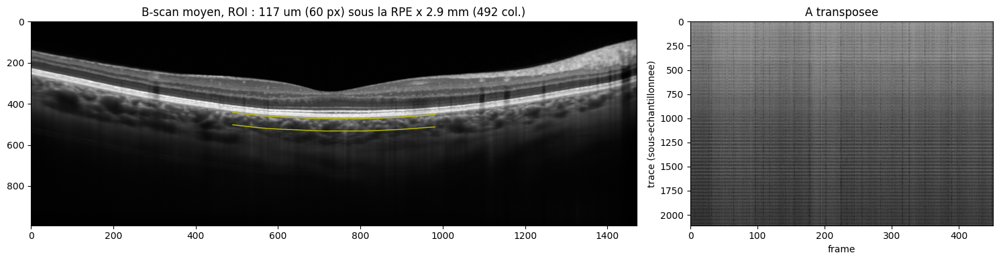

In [7]:
depth, c0, c1 = pc.roi_pixels(W, ds.pixel_mm)
keep_cols = mask[:, :, c0:c1].any(axis=1).any(axis=0)
nc = int(keep_cols.sum())
A = pc.rpe_band_traces(frames, mask, ds.pixel_mm)        # (T, depth * nc), ordre (profondeur, colonne)
mean_intensity = A.mean(axis=1).astype(np.float64)
print(f"A : {A.shape} = {T} frames x ({depth} px de profondeur x {nc} colonnes)")

# Ou est la region : B-scan moyen, bord superieur median du masque, ROI.
has = mask.any(axis=1)
top = np.full(W, np.nan)
top[has.any(axis=0)] = np.nanmedian(np.where(has, mask.argmax(axis=1), np.nan)[:, has.any(axis=0)], axis=0)
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw=dict(width_ratios=[2, 1]))
ax[0].imshow(frames.mean(axis=0), cmap="gray", aspect="auto")
cols = np.arange(c0, c1)
ax[0].plot(cols, top[c0:c1], "y-", lw=1)
ax[0].plot(cols, top[c0:c1] + depth, "y-", lw=1)
ax[0].set_title(f"B-scan moyen, ROI : {ROI_DEPTH_UM:.0f} um ({depth} px) sous la RPE x {ROI_WIDTH_MM} mm ({c1 - c0} col.)")
ax[1].imshow(A[:, :: max(1, A.shape[1] // 2000)].T, cmap="gray", aspect="auto")
ax[1].set_xlabel("frame"); ax[1].set_ylabel("trace (sous-echantillonnee)"); ax[1].set_title("A transposee")
plt.tight_layout(); plt.show()

### 1 bis. `normalized_trace`

`PixelTraceSource` lit ses traces dans `registered_frames[registered_masks]` ; on lui donne `A`
comme une vidéo d'une ligne (masque plein), si bien que `normalized_trace()` est exactement la
méthode du package appliquée à la ROI de l'app. Ce qu'elle retire : l'intensité moyenne de la
ROI à chaque frame (à gauche), pic à la FC compris (à droite).

In [8]:
class _RoiVideo:
    # Juste ce que PixelTraceSource et VideoTimelineAligner lisent.
    skip_first_n_frames = 0
    drop_last_n_frames = 0

    def __init__(self, X):
        self.registered_frames = X[:, None, :]
        self.registered_masks = np.ones(self.registered_frames.shape, bool)


roi_video = _RoiVideo(A)
aligner = VideoTimelineAligner(roi_video, t - t[0], units_in_timestamps=TimeUnits.SECONDS)
A_norm = PixelTraceSource(roi_video, aligner).normalized_trace()      # (T, N), moyenne spatiale = 1
SOURCES = {"non normalisé": A.astype(np.float64), "normalized_trace": A_norm}
print(f"normalized_trace : {A_norm.shape}, moyenne spatiale par frame dans "
      f"[{A_norm.mean(axis=1).min():.4f}, {A_norm.mean(axis=1).max():.4f}]")

fig = make_subplots(rows=1, cols=2, subplot_titles=(
    "intensite moyenne de la ROI par frame (retiree par normalized_trace)", "son spectre"))
fig.add_trace(go.Scatter(x=t, y=mean_intensity, name="intensite moyenne", line=dict(color="black", width=1.2)), 1, 1)
fig.add_trace(go.Scatter(x=bpm, y=pc._ls(t, mean_intensity, freqs), showlegend=False,
                         line=dict(color="black", width=1.2)), 1, 2)
fig.add_vrect(x0=BAND_HR_BPM[0], x1=BAND_HR_BPM[1], fillcolor="orange", opacity=0.2, line_width=0, row=1, col=2)
fig.update_xaxes(title_text="temps (s)", row=1, col=1)
fig.update_xaxes(title_text="BPM", row=1, col=2)
fig.update_layout(template="plotly_white", height=330)
fig.show()

normalized_trace : (451, 29520), moyenne spatiale par frame dans [1.0000, 1.0000]


## 2. FIR sur la dimension temporelle

Les horodatages ne sont pas parfaitement réguliers : chaque trace est interpolée sur la grille
uniforme `u` avant le FIR (le FIR suppose un pas constant). La variante `brut` garde `A` sur ses
horodatages réels, exactement comme l'app. Dans tous les cas chaque trace est ensuite
centrée-réduite, comme dans `pulse_compute.svd_components`.

Le FIR est appliqué par `filtfilt` : aucun déphasage, mais un transitoire aux bords (un
nombre de prises de l'ordre de 4 fs / f_bas), visible au début et à la fin des traces.

In [9]:
def standardize(X):
    X = X - X.mean(axis=0, keepdims=True)
    return X / (X.std(axis=0, keepdims=True) + 1e-6)


def fir_matrix(X, band_bpm):
    nyq = 0.5 * fs
    lo, hi = band_bpm[0] / 60.0 / nyq, min(band_bpm[1] / 60.0 / nyq, 0.99)
    Xu = interp1d(t, X, axis=0, assume_sorted=True)(u).astype(np.float64)
    return spatio_temporal_filter(Xu, 0.0, lo, hi, fs, None)


mats, times = {}, {}
for name, (norm, fir) in VARIANTS.items():
    band, X0 = FIRS[fir], SOURCES[norm]
    if band is None:
        mats[name], times[name] = standardize(X0), t
    else:
        mats[name], times[name] = standardize(fir_matrix(X0, band)), u
    print(f"{name:>32} : {mats[name].shape}, bande {band}")

rng = np.random.default_rng(0)
pick = rng.choice(A.shape[1], size=min(N_PIX_SPECTRA, A.shape[1]), replace=False)
fig = make_subplots(rows=1, cols=2, subplot_titles=(
    "une trace (meme pixel, centree-reduite)", f"spectre moyen de {pick.size} traces (Lomb-Scargle)"))
for name, X in mats.items():
    tt = times[name]
    fig.add_trace(go.Scatter(x=tt, y=X[:, pick[0]], name=name, legendgroup=name,
                             line=dict(color=COLORS[name], dash=DASH[name], width=1.2)), row=1, col=1)
    P = np.mean([pc._ls(tt, X[:, j], freqs) for j in pick], axis=0)
    fig.add_trace(go.Scatter(x=bpm, y=P, name=name, legendgroup=name, showlegend=False,
                             line=dict(color=COLORS[name], dash=DASH[name], width=1.5)), row=1, col=2)
for b in (BAND_HR_BPM, BAND_WIDE_BPM):
    fig.add_vrect(x0=b[0], x1=b[1], fillcolor="orange" if b == BAND_HR_BPM else "lightblue",
                  opacity=0.2, line_width=0, row=1, col=2)
fig.update_xaxes(title_text="temps (s)", row=1, col=1)
fig.update_xaxes(title_text="BPM (orange : FC ±10 %, bleu : bande large)", row=1, col=2)
fig.update_layout(template="plotly_white", height=380)
fig.show()

            non normalisé | brut : (451, 29520), bande None
           non normalisé | large : (517, 29520), bande (40.0, 150.0)
        non normalisé | FC ±10 % : (517, 29520), bande (48.6, 59.400000000000006)
         normalized_trace | brut : (451, 29520), bande None
        normalized_trace | large : (517, 29520), bande (40.0, 150.0)
     normalized_trace | FC ±10 % : (517, 29520), bande (48.6, 59.400000000000006)


## 3. SVD, 100 premiers vecteurs singuliers

`U` (T × 100) : cours temporels pondérés par la valeur singulière ; `V` (N × 100) : motifs
spatiaux. Pour chaque composante, la **fraction de puissance dans la bande FC ±10 %** dit si
elle porte le pouls. Le filtre change à la fois l'énergie résiduelle (valeurs singulières) et le
rang auquel le pouls apparaît.

In [10]:
svd = {}
for name, X in mats.items():
    Uk, Vk = project_into_separable_components(X, method="svd", n_components=min(RANK, *X.shape))
    s = np.linalg.norm(Uk, axis=0)
    P = np.stack([pc._ls(times[name], Uk[:, i], freqs) for i in range(Uk.shape[1])], axis=1)
    bandfrac = P[in_band].sum(axis=0) / (P.sum(axis=0) + 1e-12)
    peak = bpm[P.argmax(axis=0)]
    svd[name] = dict(U=Uk, V=Vk, s=s, P=P, bandfrac=bandfrac, peak=peak)
    best = int(bandfrac.argmax())
    print(f"{name:>32} : energie des 100 premieres {np.sum(s**2) / np.sum(X**2):.1%} ; "
          f"meilleure composante seule n° {best + 1} ({bandfrac[best]:.0%} en bande, pic {peak[best]:.0f} BPM) ; "
          f"{int((np.abs(peak - HR) <= pc.BAND_FRAC * HR).sum())} composantes avec leur pic dans la bande")

fig = make_subplots(rows=1, cols=2, subplot_titles=(
    "valeurs singulieres (normalisees par la 1re)", "fraction de puissance dans FC ±10 %"))
k = np.arange(1, RANK + 1)
for name, d in svd.items():
    fig.add_trace(go.Scatter(x=k, y=d["s"] / d["s"][0], name=name, legendgroup=name,
                             line=dict(color=COLORS[name], dash=DASH[name])), row=1, col=1)
    fig.add_trace(go.Scatter(x=k, y=d["bandfrac"], name=name, legendgroup=name, showlegend=False,
                             mode="lines+markers", marker=dict(size=4), line=dict(color=COLORS[name], dash=DASH[name], width=1),
                             customdata=d["peak"],
                             hovertemplate="composante %{x}<br>%{y:.0%} en bande<br>pic %{customdata:.0f} BPM<extra>" + name + "</extra>"),
                  row=1, col=2)
fig.update_yaxes(type="log", row=1, col=1)
fig.update_xaxes(title_text="rang")
fig.update_layout(template="plotly_white", height=380)
fig.show()

            non normalisé | brut : energie des 100 premieres 68.9% ; meilleure composante seule n° 33 (14% en bande, pic 52 BPM) ; 22 composantes avec leur pic dans la bande
           non normalisé | large : energie des 100 premieres 84.2% ; meilleure composante seule n° 42 (37% en bande, pic 50 BPM) ; 39 composantes avec leur pic dans la bande
        non normalisé | FC ±10 % : energie des 100 premieres 100.0% ; meilleure composante seule n° 6 (99% en bande, pic 56 BPM) ; 20 composantes avec leur pic dans la bande
         normalized_trace | brut : energie des 100 premieres 67.0% ; meilleure composante seule n° 76 (15% en bande, pic 49 BPM) ; 29 composantes avec leur pic dans la bande
        normalized_trace | large : energie des 100 premieres 84.5% ; meilleure composante seule n° 29 (40% en bande, pic 52 BPM) ; 26 composantes avec leur pic dans la bande
     normalized_trace | FC ±10 % : energie des 100 premieres 100.0% ; meilleure composante seule n° 2 (100% en bande, pic 54 BPM) 

## 4. Combinaison linéaire optimisée

Même appel que l'app (`pulse_compute.optimized_combination`) : candidates = composantes dont le
pic tombe à FC ±10 % et assez concentré (seuil descendu de 0,15 à 0 si aucune ne passe),
poids ‖w‖ = 1 maximisant la puissance en bande sur 5 fenêtres de 6 cycles. Signe : corrélé
positivement à l'intensité moyenne brute de la région.

Référence indépendante : le pouls d'**épaisseur des masques**, filtré FC ±10 %. Pour comparer à
armes égales, le pouls de chaque variante passe aussi par ce FIR final avant le déphasage.

In [11]:
thick = pc.mask_thickness(mask, ds.pixel_mm[0])
ok = np.isfinite(thick)
thick = np.interp(t, t[ok], thick[ok])
thick_f = pc._fir(thick - thick.mean(), t, u, fs, BAND_HR_BPM)

res, rows = {}, []
for name, d in svd.items():
    tt = times[name]
    y, r, min_conc = pc.optimized_combination(d["U"], d["V"], tt, HR)
    w = np.asarray(r.weights, float)
    mi = mean_intensity if tt is t else np.interp(tt, t, mean_intensity)
    if np.corrcoef(y, mi)[0, 1] < 0:
        y, w = -y, -w
    y = y - y.mean()
    y_t = y if tt is t else np.interp(t, tt, y)                 # ramene sur les frames
    y_f = pc._fir(y_t, t, u, fs, BAND_HR_BPM)
    ph = pc.phase_difference(thick_f, y_f, f0)
    spec = pc._ls(tt, y, freqs)
    res[name] = dict(y=y, t=tt, y_f=y_f, ch=np.asarray(r.selected_indices, int), w=w, ph=ph,
                     spec=spec, min_conc=min_conc)
    rows.append({"variante": name, "composantes retenues": len(r.selected_indices),
                 "seuil concentration": min_conc,
                 "puissance en bande (pouls)": spec[in_band].sum() / spec.sum(),
                 "meilleure composante seule": d["bandfrac"].max(),
                 "dphi vs epaisseur (deg)": np.degrees(ph.mean), "PLV vs epaisseur": ph.plv,
                 "corr vs epaisseur (coeur)": np.corrcoef(y_f[ph.core], thick_f[ph.core])[0, 1],
                 "corr vs epaisseur (tout)": np.corrcoef(y_f, thick_f)[0, 1]})
summary = pd.DataFrame(rows).set_index("variante")
summary.style.format({"puissance en bande (pouls)": "{:.0%}", "meilleure composante seule": "{:.0%}",
                      "dphi vs epaisseur (deg)": "{:+.0f}", "PLV vs epaisseur": "{:.2f}",
                      "corr vs epaisseur (coeur)": "{:+.2f}", "corr vs epaisseur (tout)": "{:+.2f}",
                      "seuil concentration": "{:.2f}"})

,composantes retenues,seuil concentration,puissance en bande (pouls),meilleure composante seule,dphi vs epaisseur (deg),PLV vs epaisseur,corr vs epaisseur (coeur),corr vs epaisseur (tout)
variante,,,,,,,,
non normalisé | brut,12,0.10,23%,14%,-114,0.75,-0.41,-0.34
non normalisé | large,12,0.15,36%,37%,+94,0.39,-0.02,+0.22
non normalisé | FC ±10 %,12,0.15,98%,99%,-94,0.10,+0.05,-0.02
normalized_trace | brut,1,0.15,13%,15%,-91,0.40,-0.06,-0.03
normalized_trace | large,12,0.15,43%,40%,-114,0.59,-0.28,-0.56
normalized_trace | FC ±10 %,12,0.15,98%,100%,-127,0.50,-0.34,-0.37


In [12]:
fig = make_subplots(rows=2, cols=1, shared_xaxes=False, vertical_spacing=0.12, subplot_titles=(
    "pouls optimises (centres-reduits) et epaisseur des masques, apres FIR FC ±10 %",
    "spectre du pouls optimise AVANT le FIR final"))
z = lambda a: (a - a.mean()) / (a.std() + 1e-12)
fig.add_trace(go.Scatter(x=u, y=z(thick_f), name="epaisseur des masques", line=dict(color="black", dash="dot")), 1, 1)
for name, r in res.items():
    fig.add_trace(go.Scatter(x=u, y=z(r["y_f"]), name=name, legendgroup=name,
                             line=dict(color=COLORS[name], dash=DASH[name], width=1.5)), 1, 1)
    fig.add_trace(go.Scatter(x=bpm, y=r["spec"], name=name, legendgroup=name, showlegend=False,
                             line=dict(color=COLORS[name], dash=DASH[name], width=1.5)), 2, 1)
fig.add_vrect(x0=BAND_HR_BPM[0], x1=BAND_HR_BPM[1], fillcolor="orange", opacity=0.2, line_width=0, row=2, col=1)
fig.update_xaxes(title_text="temps (s)", row=1, col=1)
fig.update_xaxes(title_text="BPM", row=2, col=1)
fig.update_layout(template="plotly_white", height=650)
fig.show()

## 5. Les vecteurs singuliers retenus

Pour chaque variante : poids de la combinaison (barres, rang de la composante en abscisse),
puis les `N_SHOW` composantes de plus fort |poids| : cours temporel, spectre, et carte
spatiale (colonne de `V` remise en profondeur × colonne ; rouge / bleu = signe du motif).
Le motif spatial de la combinaison entière (`V[:, retenues] @ w`) est la dernière carte.

In [13]:
fig = go.Figure()
for name, r in res.items():
    fig.add_trace(go.Bar(x=r["ch"] + 1, y=r["w"], name=name, marker_color=COLORS[name],
                         marker_pattern_shape="" if VARIANTS[name][0] == NORMS[0] else ".",
                         hovertemplate="composante %{x}<br>poids %{y:.3f}<extra>" + name + "</extra>"))
fig.update_layout(template="plotly_white", height=320, barmode="group",
                  title="poids des composantes retenues (||w|| = 1)",
                  xaxis_title="rang de la composante", yaxis_title="poids")
fig.show()

In [14]:
def show_components(name):
    d, r = svd[name], res[name]
    order = np.argsort(-np.abs(r["w"]))[:N_SHOW]
    comps = r["ch"][order]
    n = len(comps)
    fig = make_subplots(rows=n, cols=2, horizontal_spacing=0.08, vertical_spacing=0.04,
                        subplot_titles=[s for c, w_ in zip(comps, r["w"][order]) for s in (
                            f"composante {c + 1} (poids {w_:+.2f}, {d['bandfrac'][c]:.0%} en bande)",
                            f"spectre, pic {d['peak'][c]:.0f} BPM")])
    for i, c in enumerate(comps, 1):
        fig.add_trace(go.Scatter(x=r["t"], y=d["U"][:, c], showlegend=False,
                                 line=dict(color=COLORS[name], width=1)), i, 1)
        fig.add_trace(go.Scatter(x=bpm, y=d["P"][:, c], showlegend=False,
                                 line=dict(color=COLORS[name], width=1)), i, 2)
        fig.add_vrect(x0=BAND_HR_BPM[0], x1=BAND_HR_BPM[1], fillcolor="orange", opacity=0.2,
                      line_width=0, row=i, col=2)
    fig.update_xaxes(title_text="temps (s)", row=n, col=1)
    fig.update_xaxes(title_text="BPM", row=n, col=2)
    fig.update_layout(template="plotly_white", height=170 * n + 80,
                      title=f"{name} : composantes retenues de plus fort poids")
    fig.show()

    maps = [d["V"][:, c].reshape(depth, nc) for c in comps]
    maps.append((d["V"][:, r["ch"]] @ r["w"]).reshape(depth, nc))
    titles = [f"composante {c + 1}" for c in comps] + ["combinaison (V w)"]
    fig = make_subplots(rows=len(maps), cols=1, vertical_spacing=0.03, subplot_titles=titles)
    x_mm = np.arange(nc) * ds.pixel_mm[1]
    y_um = np.arange(depth) * ds.pixel_mm[0] * 1e3
    for i, m in enumerate(maps, 1):
        v = float(np.abs(m).max()) or 1.0
        fig.add_trace(go.Heatmap(z=m, x=x_mm, y=y_um, colorscale="RdBu_r", zmin=-v, zmax=v,
                                 showscale=False,
                                 hovertemplate="%{x:.2f} mm, %{y:.0f} um sous la RPE<br>%{z:.2e}<extra></extra>"),
                      i, 1)
        fig.update_yaxes(autorange="reversed", title_text="um", row=i, col=1)
    fig.update_xaxes(title_text="position laterale dans la ROI (mm, colonnes sans masque retirees)",
                     row=len(maps), col=1)
    fig.update_layout(template="plotly_white", height=150 * len(maps) + 80,
                      title=f"{name} : motifs spatiaux (profondeur x colonne)")
    fig.show()


for name in VARIANTS:
    if VARIANTS[name][0] == NORMS[0]:
        show_components(name)

In [15]:
for name in VARIANTS:
    if VARIANTS[name][0] == NORMS[1]:
        show_components(name)

## Lecture

* **Valeurs singulières / fraction en bande** (§3) : avec le FIR, le pouls doit apparaître à un
  rang plus bas et avec une fraction en bande plus haute ; avec `FC ±10 %`, toutes les
  composantes sont en bande par construction -- la fraction en bande ne discrimine plus rien et
  l'optimisation choisit entre des sinusoïdes de même fréquence.
* **Tableau** (§4) : la colonne qui compte est l'accord avec l'épaisseur des masques (PLV,
  déphasage, corrélation), pas la puissance en bande, qu'un FIR étroit gonfle mécaniquement.
* **Normalisation** : `normalized_trace` retire l'intensité moyenne de la ROI à chaque frame.
  Si le pouls d'intensité est surtout un battement *en phase* dans toute la ROI, il disparaît
  avec elle et la combinaison se rabat sur les différences entre régions (le pouls doit alors
  s'éloigner de l'épaisseur) ; s'il garde son accord avec l'épaisseur, c'est que le gain commun
  n'était que du bruit.
* **Cartes** (§5) : un vrai pouls choroïdien doit donner un motif étendu et cohérent en
  profondeur ; un motif concentré sur quelques colonnes ou sur le bord haut de la ROI signale un
  résidu de recalage (bord RPE qui bouge) plutôt qu'une pulsation d'intensité.